# Fase 1 – Exploración de datos: casos de dengue SIVIGILA (Tuluá, Valle del Cauca)

**Objetivo:** entender los datos antes de modelar. En esta fase **no se entrena ningún modelo**.

**Fuente:** datos.gov.co, conjunto `dq2k-gub9`, *Registro de Casos de Dengue en el Municipio de Tuluá*
(evento SIVIGILA 210 = dengue). Se descargó a `data/raw/dengue_tulua.csv`.

**¿Por qué Tuluá?** De los conjuntos públicos con síntomas a nivel de paciente, es el único con un número
importante de casos **descartados** por laboratorio (`ajuste_ = 6`). Esos casos son la clase negativa
que necesitamos para responder "¿dengue sí o no?". Bucaramanga, por ejemplo, tiene solo 1 descartado.

> Para descargar de nuevo: `https://www.datos.gov.co/resource/dq2k-gub9.csv?$limit=100000`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

df = pd.read_csv("../data/raw/dengue_tulua.csv", low_memory=False)
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
df.head(3)

Filas: 24,547  |  Columnas: 69


,cod_eve,fec_not,semana,grup_etario,clas_edad,rango_edad,a_o,nacionali_,nombre_nacionalidad,sexo_,tip_ss_,cod_ase_,per_etn_,estrato_,gp_discapa,gp_desplaz,gp_migrant,gp_carcela,gp_indigen,gp_pobicbf,gp_mad_com,gp_desmovi,gp_psiquia,gp_vic_vio,gp_otros,fuente_,cod_pais_r,cod_dpto_r,cod_mun_r,fec_con_,ini_sin_,tip_cas_,pac_hos_,con_fin_,ajuste_,desplazami,famantdngu,fiebre,cefalea,dolrretroo,malgias,artralgia,erupcionr,dolor_abdo,vomito,diarrea,somnolenci,hipotensio,hepatomeg,hem_mucosa,hipotermia,aum_hemato,caida_plaq,acum_liqui,extravasac,hemorr_hem,choque,da_o_organ,muesttejid,mueshigado,muesbazo,muespulmon,muescerebr,muesmiocar,muesmedula,muesri_on,clasfinal,conducta,nmun_resi
0,210,2023-06-12T00:00:00.000,23,12-17,Adolecencia,10-14,2023.0,170,COLOMBIA,F,S,EPSS05,6,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1,1,170.0,76,834,2023-06-10T00:00:00.000,2023-06-06T00:00:00.000,3,1,1,0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,TULUA
1,210,2023-04-04T00:00:00.000,13,29-59,Adultes,50-59,2023.0,170,COLOMBIA,F,E,RES001,6,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1,1,170.0,76,834,2023-04-03T00:00:00.000,2023-03-29T00:00:00.000,3,1,1,0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,TULUA
2,210,2023-08-04T00:00:00.000,31,12-17,Adolecencia,10-14,2023.0,170,COLOMBIA,M,S,EPSS37,6,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1,1,170.0,76,834,2023-08-04T00:00:00.000,2023-07-30T00:00:00.000,3,1,1,0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,3.0,TULUA


## 1. Columnas y tipos de dato

In [2]:
info = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True),
})
info

,tipo,nulos,% nulos,valores_unicos
cod_eve,int64,0,0.00,1
fec_not,str,0,0.00,1072
semana,int64,0,0.00,52
grup_etario,str,0,0.00,6
clas_edad,str,0,0.00,7
...,...,...,...,...
muesmedula,float64,191,0.78,1
muesri_on,float64,191,0.78,1
clasfinal,float64,1,0.00,2
conducta,float64,5,0.02,5


### Diccionario de códigos SIVIGILA (ficha de notificación 210)

| Columna | Significado | Códigos |
|---|---|---|
| `tip_cas_` | Tipo de caso al notificar | 2 = Probable, 3 = Confirmado por laboratorio, 5 = Confirmado por nexo epidemiológico |
| `ajuste_` | Ajuste posterior del caso | 0 = Sin ajuste, 3 = Confirmado por laboratorio, 5 = Confirmado por nexo, **6 = Descartado**, 7 = Otra actualización |
| `clasfinal` | Clasificación clínica | 1 = Dengue sin signos de alarma, 2 = Dengue con signos de alarma, 3 = Dengue grave |
| `pac_hos_` | Hospitalizado | 1 = Sí, 2 = No |
| `con_fin_` | Condición final | 1 = Vivo, 2 = Muerto |
| Síntomas (`fiebre`, `cefalea`, …) | Presencia del signo/síntoma | 1 = Sí, 2 = No |
| `famantdngu` | Familiar con dengue | 1 = Sí, 2 = No, 3 = Desconoce |
| `desplazami` | Desplazamiento a zona endémica | 1 = Sí, 2 = No |

**Ojo:** los síntomas vienen codificados como **1 = Sí / 2 = No**, no como 1/0. En la Fase 2 se normalizan a 0/1.

## 2. Valores nulos

In [3]:
nulos = info[info["nulos"] > 0].sort_values("nulos", ascending=False)
nulos

,tipo,nulos,% nulos,valores_unicos
a_o,float64,18830,76.71,4
estrato_,float64,260,1.06,6
mueshigado,float64,191,0.78,1
da_o_organ,float64,191,0.78,1
choque,float64,191,0.78,1
hemorr_hem,float64,191,0.78,1
extravasac,float64,191,0.78,1
muesri_on,float64,191,0.78,1
muescerebr,float64,191,0.78,1
muesmiocar,float64,191,0.78,1


**Lectura:**
- `a_o` (año) tiene ~77 % nulos; no importa, porque el año se puede sacar de `fec_not` (fecha de notificación).
- Las variables de dengue grave (`extravasac`, `choque`, `da_o_organ`, `mues*`) tienen 191 nulos. Igual
  **no se usarán**: son hallazgos clínicos posteriores (fuga de información).
- Los síntomas tempranos **no tienen nulos**. Aun así, el pipeline de la Fase 2 manejará nulos por robustez
  (por ejemplo, si un formulario llega incompleto).

## 3. Variables de clasificación del caso

In [4]:
for col in ["cod_eve", "tip_cas_", "ajuste_", "clasfinal", "con_fin_", "pac_hos_", "conducta"]:
    print(f"--- {col}")
    print(df[col].value_counts(dropna=False).sort_index().to_string(), "\n")

--- cod_eve
cod_eve
210    24547 

--- tip_cas_
tip_cas_
2    12533
3    11987
5       27 

--- ajuste_
ajuste_
0    14187
3     2647
5        9
6     6143
7     1561 

--- clasfinal
clasfinal
1.0    13595
2.0    10951
NaN        1 

--- con_fin_
con_fin_
1    24547 

--- pac_hos_
pac_hos_
1    10774
2    13773 

--- conducta
conducta
1.0    7795
2.0    7716
3.0    1643
4.0    6992
5.0     396
NaN       5 



In [5]:
print("tip_cas_ (filas) vs ajuste_ (columnas):")
pd.crosstab(df["tip_cas_"], df["ajuste_"], margins=True)

tip_cas_ (filas) vs ajuste_ (columnas):


ajuste_,0,3,5,6,7,All
tip_cas_,,,,,,
2,4025,1969,9,6110,420,12533
3,10141,678,0,30,1138,11987
5,21,0,0,3,3,27
All,14187,2647,9,6143,1561,24547


**Lectura:**
- Todos los registros son evento 210 (dengue) y todos los pacientes terminaron vivos (`con_fin_ = 1`).
- `tip_cas_` es el tipo de caso **al notificar**. `ajuste_` es la **corrección posterior**, normalmente cuando
  llega el resultado de laboratorio. Por eso `ajuste_` manda: hay 30 casos notificados como "confirmados" (3)
  que luego fueron descartados (6).
- `clasfinal` solo tiene 1 y 2 (no hay dengue grave). Aparece incluso en casos descartados porque se llena al
  notificar, así que **no sirve como etiqueta de dengue sí/no**.

## 4. ¿Existen casos DESCARTADOS (no dengue)? → Sí

In [6]:
df = df.drop_duplicates()
print(f"Filas tras quitar duplicados exactos: {len(df):,}")

descartado = df["ajuste_"] == 6
confirmado = ~descartado & (df["tip_cas_"].isin([3, 5]) | df["ajuste_"].isin([3, 5]))

df["clase"] = "Excluido (probable sin confirmar)"
df.loc[confirmado, "clase"] = "Dengue confirmado (1)"
df.loc[descartado, "clase"] = "Descartado (0)"

dist = df["clase"].value_counts().to_frame("casos")
dist["%"] = (dist["casos"] / dist["casos"].sum() * 100).round(1)
dist

Filas tras quitar duplicados exactos: 23,660


,casos,%
clase,,
Dengue confirmado (1),13200,55.8
Descartado (0),6140,26.0
Excluido (probable sin confirmar),4320,18.3


**Definición propuesta de la variable objetivo (`dengue`)**

| Clase | Regla | Razón |
|---|---|---|
| **1 = Dengue** | no descartado **y** (confirmado al notificar `tip_cas_ ∈ {3,5}` **o** confirmado por ajuste `ajuste_ ∈ {3,5}`) | El laboratorio o el nexo epidemiológico confirman dengue |
| **0 = No dengue** | `ajuste_ = 6` | El caso se investigó y se descartó |
| *Excluido* | sigue "probable" sin ajuste confirmatorio | Nunca se confirmó ni se descartó: incluirlo como 0 o como 1 metería **ruido en la etiqueta** |

**Interpretación importante para la sustentación:** los descartados no son personas sanas. Son pacientes que
consultaron con **fiebre** y síntomas compatibles, pero a quienes el laboratorio les dio negativo (probablemente
otra virosis). Por eso el modelo responde:
*"Dado un paciente febril con estos síntomas, ¿qué tan probable es que sea dengue y no otra enfermedad febril?"*.

dengue
dengue       13200
no dengue     6140
Name: count, dtype: int64

Proporción de la clase positiva: 68.3%


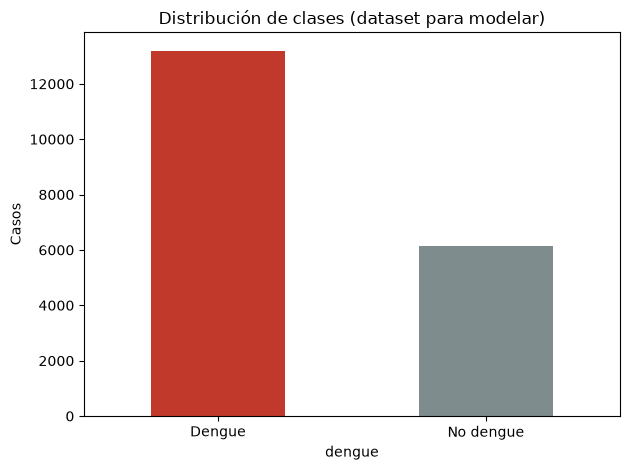

In [7]:
modelo = df[df["clase"] != "Excluido (probable sin confirmar)"].copy()
modelo["dengue"] = (modelo["clase"] == "Dengue confirmado (1)").astype(int)
print(modelo["dengue"].value_counts().rename({1: "dengue", 0: "no dengue"}))
print(f"\nProporción de la clase positiva: {modelo['dengue'].mean():.1%}")

ax = modelo["dengue"].map({1: "Dengue", 0: "No dengue"}).value_counts().plot.bar(color=["#c0392b", "#7f8c8d"], rot=0)
ax.set_title("Distribución de clases (dataset para modelar)")
ax.set_ylabel("Casos")
plt.tight_layout(); plt.show()

**Desbalance:** aproximadamente 70 % dengue / 30 % no dengue. Es un desbalance **moderado** (no extremo).
En la Fase 2 se maneja con `class_weight="balanced"` y validación cruzada **estratificada**, que mantiene la
misma proporción de clases en cada pliegue.

## 5. Variables candidatas: edad y sexo

In [8]:
print("Columnas de edad disponibles:", [c for c in df.columns if "edad" in c or "etario" in c])
print(modelo["grup_etario"].value_counts().sort_index().to_string())
pd.crosstab(modelo["grup_etario"], modelo["dengue"], normalize="index").round(3).rename(columns={0: "% no dengue", 1: "% dengue"})

Columnas de edad disponibles: ['grup_etario', 'clas_edad', 'rango_edad']
grup_etario
0-5      1897
12-17    4273
18-28    4031
29-59    3948
6-11     3927
60+      1264


dengue,% no dengue,% dengue
grup_etario,,
0-5,0.390,0.610
12-17,0.248,0.752
18-28,0.313,0.687
29-59,0.375,0.625
6-11,0.284,0.716
60+,0.384,0.616


**Limitación:** este conjunto **no trae la edad exacta** (se anonimizó). Solo trae rangos. `grup_etario` tiene
6 rangos consistentes (`0-5, 6-11, 12-17, 18-28, 29-59, 60+`). `rango_edad` mezcla dos esquemas distintos, así que
se descarta. En la Fase 2 se usará `grup_etario`. En el formulario web se pedirá la edad en años y se
convertirá al rango correspondiente.

In [9]:
pd.crosstab(modelo["sexo_"], modelo["dengue"], normalize="index").round(3).rename(columns={0: "% no dengue", 1: "% dengue"})

dengue,% no dengue,% dengue
sexo_,,
F,0.325,0.675
M,0.310,0.690


## 6. Síntomas: ¿cuáles diferencian dengue de no dengue?

In [10]:
SINTOMAS = {
    "fiebre": "Fiebre", "cefalea": "Dolor de cabeza", "dolrretroo": "Dolor detrás de los ojos",
    "malgias": "Dolor muscular", "artralgia": "Dolor articular", "erupcionr": "Erupción en la piel",
    "dolor_abdo": "Dolor abdominal", "vomito": "Vómito", "diarrea": "Diarrea",
    "somnolenci": "Somnolencia", "hipotensio": "Hipotensión", "hepatomeg": "Hepatomegalia",
    "hem_mucosa": "Sangrado de mucosas", "hipotermia": "Hipotermia", "aum_hemato": "Aumento hematocrito",
    "caida_plaq": "Caída de plaquetas", "acum_liqui": "Acumulación de líquidos",
    "famantdngu": "Familiar con dengue", "desplazami": "Viajó a zona endémica",
}
prev = pd.DataFrame({
    "% en dengue": (modelo.loc[modelo.dengue == 1, list(SINTOMAS)] == 1).mean() * 100,
    "% en no dengue": (modelo.loc[modelo.dengue == 0, list(SINTOMAS)] == 1).mean() * 100,
})
prev["diferencia (pp)"] = prev["% en dengue"] - prev["% en no dengue"]
prev.index = [f"{SINTOMAS[c]} ({c})" for c in prev.index]
prev.round(1).sort_values("diferencia (pp)", ascending=False)

,% en dengue,% en no dengue,diferencia (pp)
Caída de plaquetas (caida_plaq),26.3,7.7,18.7
Erupción en la piel (erupcionr),25.0,14.7,10.3
Dolor abdominal (dolor_abdo),29.6,20.0,9.6
Dolor de cabeza (cefalea),81.6,75.5,6.1
Dolor detrás de los ojos (dolrretroo),34.3,29.0,5.4
Vómito (vomito),18.1,13.7,4.4
Aumento hematocrito (aum_hemato),2.7,0.4,2.2
Sangrado de mucosas (hem_mucosa),5.0,3.5,1.5
Viajó a zona endémica (desplazami),1.2,0.3,1.0
Hepatomegalia (hepatomeg),1.5,0.5,0.9


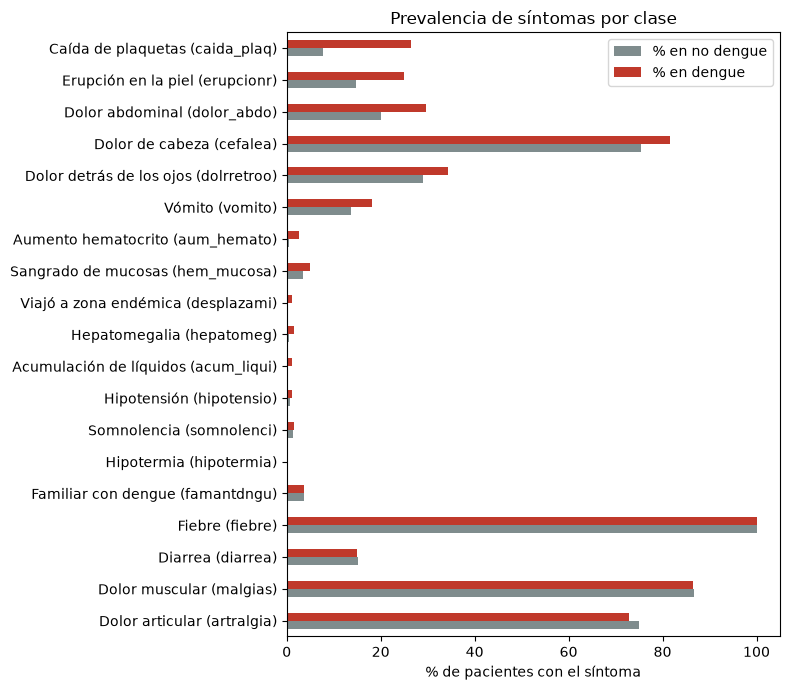

In [11]:
p = prev.sort_values("diferencia (pp)")
ax = p[["% en no dengue", "% en dengue"]].plot.barh(figsize=(8, 7), color=["#7f8c8d", "#c0392b"])
ax.set_xlabel("% de pacientes con el síntoma"); ax.set_title("Prevalencia de síntomas por clase")
plt.tight_layout(); plt.show()

**Lectura (importante para las expectativas del modelo):**
- **Fiebre está en el 100 % de los casos.** Es criterio de entrada para notificar dengue, así que **no aporta
  información** y se excluirá como variable.
- La diferencia más grande es **caída de plaquetas** (~26 % vs ~8 %). Pero es un **resultado de laboratorio**
  (hemograma), no un síntoma que el paciente pueda reportar. Ver decisión pendiente abajo.
- Entre los síntomas reportables, los que más separan son **erupción**, **dolor abdominal**, **cefalea**,
  **dolor retro-ocular** y **vómito**, con diferencias de 4 a 10 puntos porcentuales.
- Dolor muscular, dolor articular y diarrea son **casi iguales** en ambas clases: las otras virosis febriles
  también los causan.
- **Conclusión honesta:** con solo síntomas reportables, la señal es **moderada**. Hay que esperar un ROC-AUC
  aproximado de 0,60 a 0,70, no de 0,90. Es coherente con la medicina: el dengue se confirma con laboratorio
  precisamente porque los síntomas solos no bastan.

## 7. Distribución temporal y calidad de fechas

In [12]:
modelo["anio_not"] = pd.to_datetime(modelo["fec_not"]).dt.year
t = pd.crosstab(modelo["anio_not"], modelo["dengue"]).rename(columns={0: "no dengue", 1: "dengue"})
t["% dengue"] = (t["dengue"] / t.sum(axis=1) * 100).round(1)
t

dengue,no dengue,dengue,% dengue
anio_not,,,
2023,1020,2003,66.3
2024,4214,10963,72.2
2025,734,199,21.3
2026,172,35,16.9


In [13]:
dias = (pd.to_datetime(df["fec_not"]) - pd.to_datetime(df["ini_sin_"])).dt.days
dias.describe()

count    23660.000000
mean         9.547506
std         14.775047
min          0.000000
25%          3.000000
50%          5.000000
75%          8.000000
max        397.000000
dtype: float64

**Lectura:**
- La mayoría de los casos son de **2024** (año epidémico en Colombia).
- En **2025–2026** la proporción de dengue confirmado baja mucho. Es posible que haya más casos aún "en estudio"
  o un cambio en la política de pruebas. Lo anotamos como **limitación**: la mezcla de clases cambia en el tiempo.
- La mediana entre inicio de síntomas y notificación es de 5 días.

## 8. Clasificación de variables para la Fase 2

| Grupo | Variables | Decisión |
|---|---|---|
| **Entrada (formulario)** | `grup_etario`, `sexo_`, `cefalea`, `dolrretroo`, `malgias`, `artralgia`, `erupcionr`, `dolor_abdo`, `vomito`, `diarrea`, `somnolenci`, `hem_mucosa` | Usar |
| Contexto reportable (opcional) | `famantdngu`, `desplazami` | Por decidir (casi no difieren entre clases) |
| Sin información | `fiebre` | Excluir (constante = 1) |
| **Laboratorio / examen médico** | `caida_plaq`, `aum_hemato`, `hipotensio`, `hepatomeg`, `acum_liqui`, `hipotermia` | **Decisión pendiente** (ver abajo) |
| **Fuga de información** | `choque`, `da_o_organ`, `extravasac`, `hemorr_hem`, `clasfinal`, `conducta`, `pac_hos_`, `con_fin_`, `tip_cas_`, `ajuste_`, `mues*` | Excluir siempre |
| Administrativas | `fec_not`, `semana`, `cod_ase_`, `estrato_`, `gp_*`, `nmun_resi`, etc. | Excluir |

### Decisión pendiente
Las variables de laboratorio o de examen médico (sobre todo `caida_plaq`) son las que más ayudarían, pero un
paciente **no puede reportarlas** en un formulario. Las opciones son:
- **A (recomendada, coherente con el enunciado):** solo síntomas reportables. El modelo es más débil, pero honesto.
- **B:** agregar `caida_plaq` como campo opcional "¿Le hicieron un hemograma y mostró plaquetas bajas?".
  Mejora el modelo, pero cambia el público del formulario a uno con exámenes previos.